# 04 · Output validation of the scraper dataset

Checks the JSONL files produced by `ibge_nomes_scraper.py` against the schema
and invariants documented in the README:

* fields `rank, nome, frequencia, percent` present, correct types;
* `rank` is non-decreasing and ties share a rank (competition ranking);
* ordering is `frequencia DESC`, ties broken by `nome DESC`;
* `percent == round(frequencia / 203,080,756 × 100, 4)`;
* minimum `frequencia` is 20 (IBGE suppresses smaller counts).

Results are shown as tables and charts, all embedded in the notebook.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebooks live in test/; the datasets live in ../data/
DATA = Path("..") / "data"
NOMES_PATH = DATA / "nomes_censo2022_nomes.jsonl"
SOBRENOMES_PATH = DATA / "nomes_censo2022_sobrenomes.jsonl"
POP_BR_2022 = 203_080_756

plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

def load_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        return pd.DataFrame([json.loads(line) for line in fh])

print("nomes:     ", NOMES_PATH.resolve())
print("sobrenomes:", SOBRENOMES_PATH.resolve())


nomes:      /home/user/nomescenso2022/data/nomes_censo2022_nomes.jsonl
sobrenomes: /home/user/nomescenso2022/data/nomes_censo2022_sobrenomes.jsonl


In [2]:
def validate(df, label):
    checks = {}
    checks["campos obrigatórios"] = set(["rank", "nome", "frequencia", "percent"]).issubset(df.columns)
    checks["rank não decrescente"] = bool(df["rank"].is_monotonic_increasing)
    checks["frequência não crescente"] = bool((df["frequencia"].diff().dropna() <= 0).all())
    # within equal frequency, names must be in descending alphabetical order
    g = df.groupby("frequencia", sort=False)["nome"].apply(list)
    checks["empates: nome DESC"] = all(names == sorted(names, reverse=True) for names in g if len(names) > 1)
    recomputed = (df["frequencia"] / POP_BR_2022 * 100).round(4)
    checks["percent recalculado"] = bool((recomputed - df["percent"]).abs().max() < 1e-4)
    checks["frequência mínima ≥ 20"] = int(df["frequencia"].min()) >= 20
    checks["nomes únicos"] = bool(df["nome"].is_unique)
    return pd.DataFrame({"dataset": label, "verificação": list(checks), "ok": list(checks.values())})

nomes = load_jsonl(NOMES_PATH)
sob = load_jsonl(SOBRENOMES_PATH)
report = pd.concat([validate(nomes, "nomes"), validate(sob, "sobrenomes")], ignore_index=True)
report

,dataset,verificação,ok
0,nomes,campos obrigatórios,True
1,nomes,rank não decrescente,True
2,nomes,frequência não crescente,True
3,nomes,empates: nome DESC,True
4,nomes,percent recalculado,True
5,nomes,frequência mínima ≥ 20,True
6,nomes,nomes únicos,True
7,sobrenomes,campos obrigatórios,True
8,sobrenomes,rank não decrescente,True
9,sobrenomes,frequência não crescente,True


In [3]:
print("Resumo:", "TODAS AS VERIFICAÇÕES PASSARAM" if report["ok"].all() else "HÁ FALHAS")
print("Contagem nomes:", len(nomes), "| sobrenomes:", len(sob))
print("Contagens esperadas (README): 128458 / 201601 →",
      len(nomes) == 128458 and len(sob) == 201601)

Resumo: TODAS AS VERIFICAÇÕES PASSARAM
Contagem nomes: 128458 | sobrenomes: 201601
Contagens esperadas (README): 128458 / 201601 → True


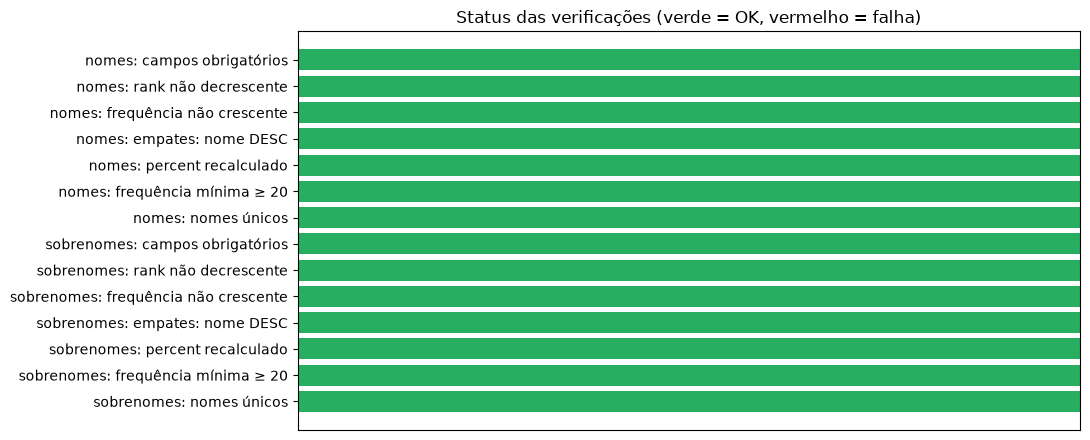

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
colors = ["#27ae60" if ok else "#c0392b" for ok in report["ok"]]
labels = [f"{d}: {v}" for d, v in zip(report["dataset"], report["verificação"])]
ax.barh(labels, [1] * len(labels), color=colors)
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.invert_yaxis()
ax.set_title("Status das verificações (verde = OK, vermelho = falha)")
plt.tight_layout()
plt.show()

nomes: resíduo máximo absoluto = 0.000000
sobrenomes: resíduo máximo absoluto = 0.000000


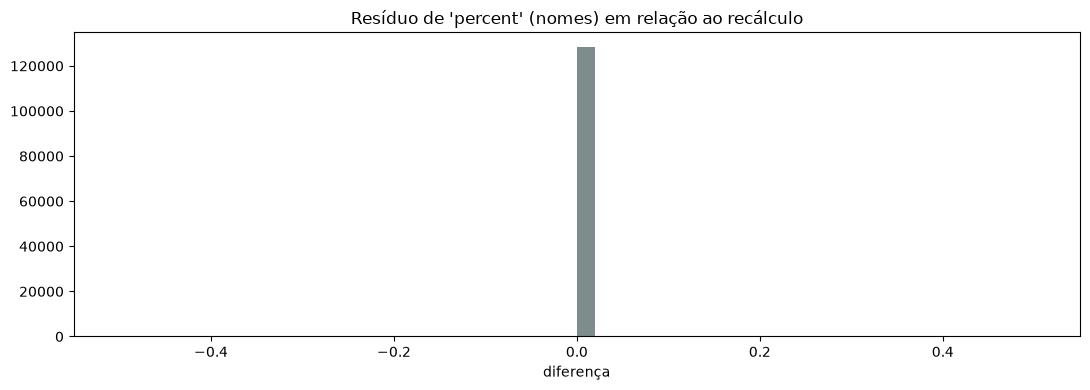

In [5]:
# Percent residual distribution: how far the stored percent is from recomputation
for name, df in (("nomes", nomes), ("sobrenomes", sob)):
    resid = (df["frequencia"] / POP_BR_2022 * 100).round(4) - df["percent"]
    print(f"{name}: resíduo máximo absoluto = {resid.abs().max():.6f}")
fig, ax = plt.subplots(figsize=(11, 4))
resid = (nomes["frequencia"] / POP_BR_2022 * 100).round(4) - nomes["percent"]
ax.hist(resid, bins=50, color="#7f8c8d")
ax.set_title("Resíduo de 'percent' (nomes) em relação ao recálculo")
ax.set_xlabel("diferença")
plt.tight_layout()
plt.show()